### Classifica celle per livello di attività. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import geopandas as gpd
import folium
import time
from pandas.plotting import lag_plot
import warnings
warnings.filterwarnings('ignore')
from sklearn import metrics
from math import sqrt

data = pd.read_csv('/Users/alket/desktop/dati/new_data_backfill_forwfill.csv', index_col = 0)
data.head()

### Aggregazione dati nei vari livelli 

In [3]:
# aggrega per numero cella
agg_by_cell = data.groupby(by = data['cell_num'])
print(len(agg_by_cell))

agg_by_date_cell = data.groupby(['date', 'cell_num'])
print(len(agg_by_date_cell))

agg_by_date_cell_hour = data.groupby(['date', 'cell_num', 'hours'])
print(len(agg_by_date_cell_hour))

221
27183
652392


### Esempi di celle con livelli di attività diversa

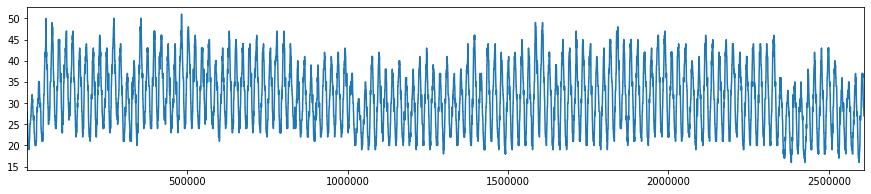

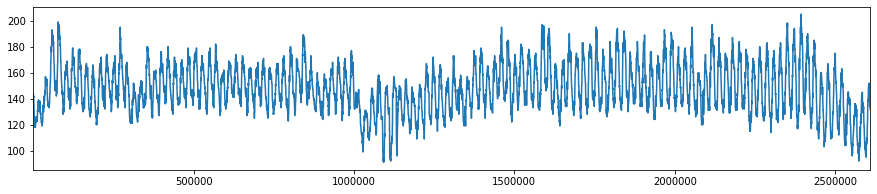

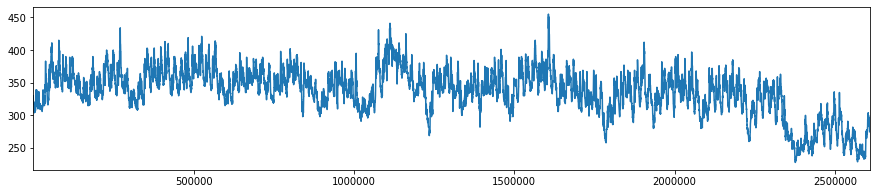

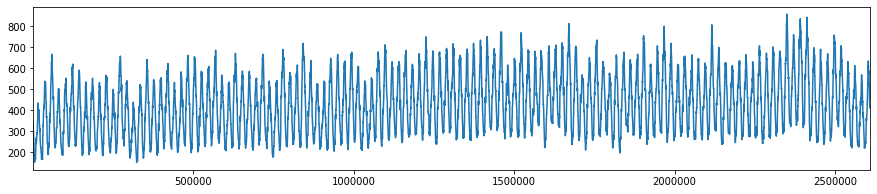

In [27]:
# livello basso
serie = agg_by_cell.get_group('490-1264')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# livello medio
serie = agg_by_cell.get_group('490-1268')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# livello alto

serie = agg_by_cell.get_group('495-1266')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# livello molto alto
serie = agg_by_cell.get_group('490-1254')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

### Celle con profili di attività diversa 

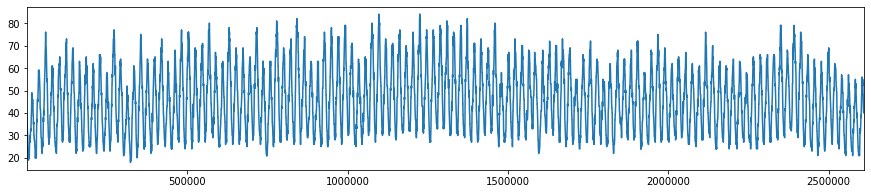

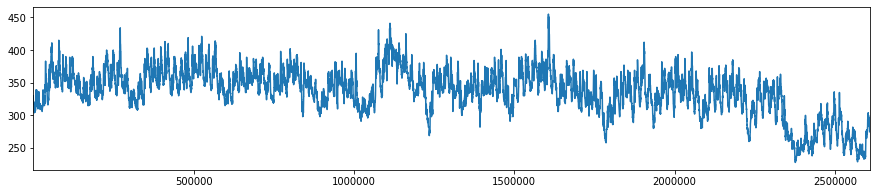

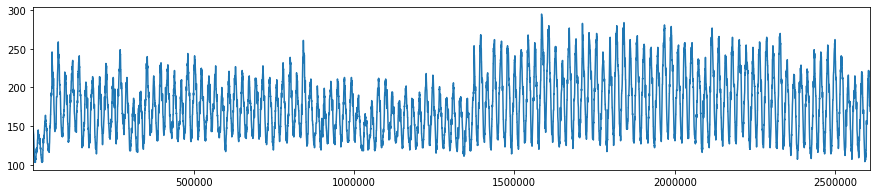

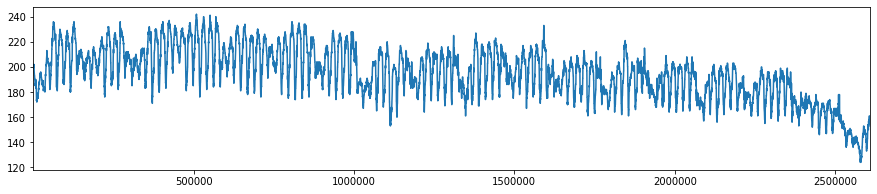

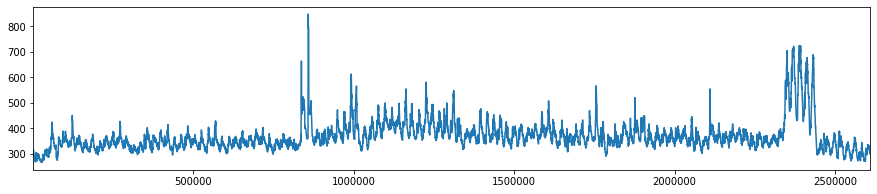

In [31]:
# livello di attività rimane invariato  per tutta la durata del periodo

serie = agg_by_cell.get_group('487-1252')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# livello di attività irregolare
serie = agg_by_cell.get_group('495-1266')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# livello di attività fà un salto per un certo periodo 

serie = agg_by_cell.get_group('489-1265')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# livello di attività che mostra il pattern lavorativo settimanale
serie = agg_by_cell.get_group('493-1268')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

# celle con eventi anche di più giorni
serie = agg_by_cell.get_group('496-1256')
serie['nr_people'].plot(figsize = (15, 3))
plt.show()

486-1252


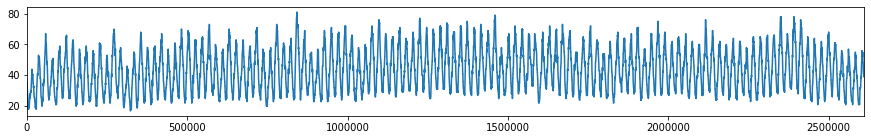

486-1253


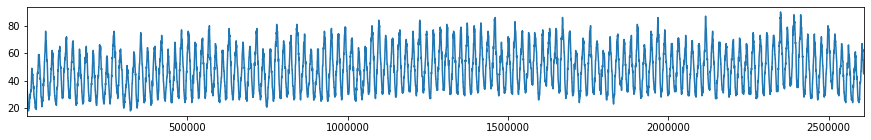

486-1254


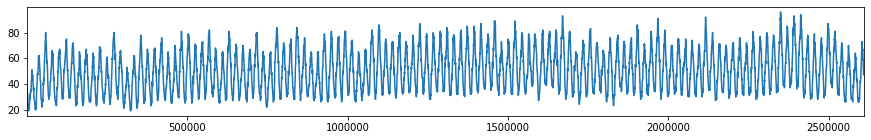

486-1255


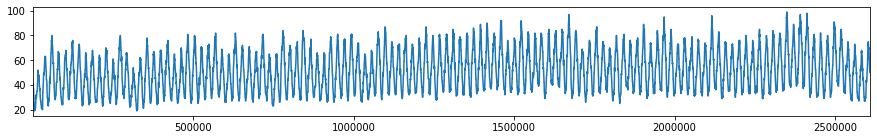

486-1256


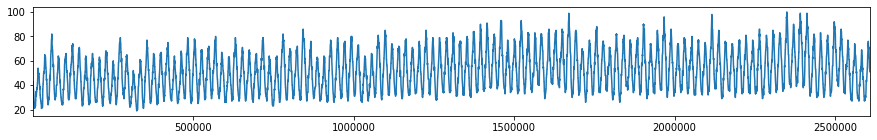

486-1257


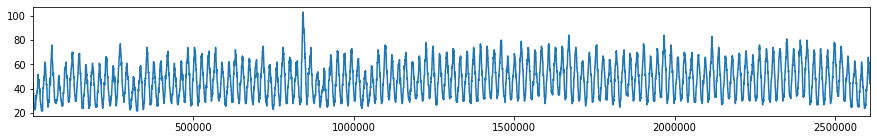

486-1258


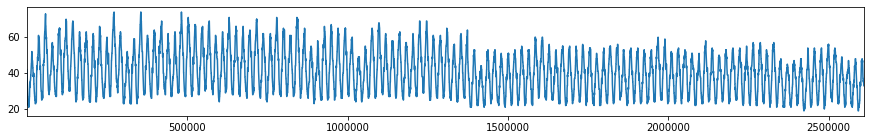

486-1259


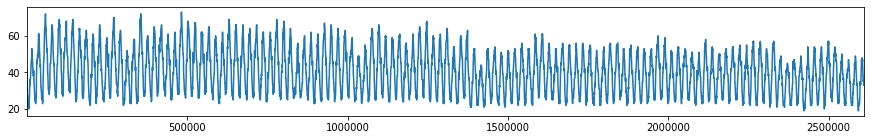

486-1260


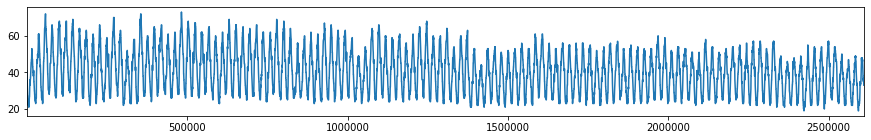

486-1261


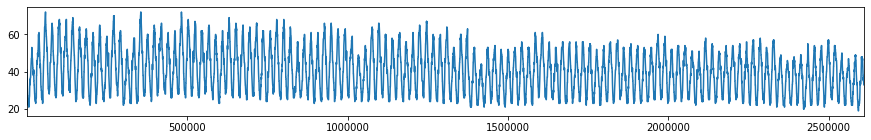

486-1262


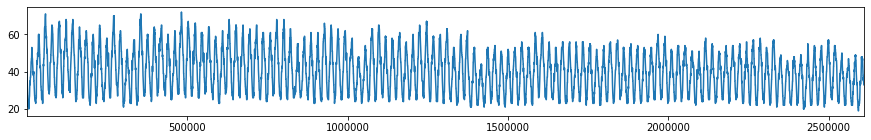

486-1263


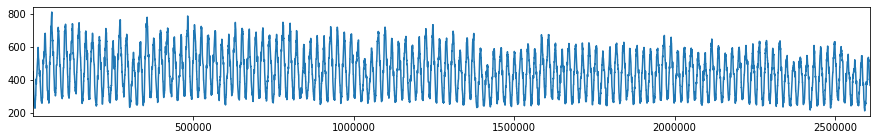

486-1264


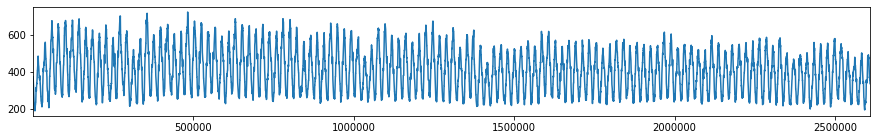

486-1265


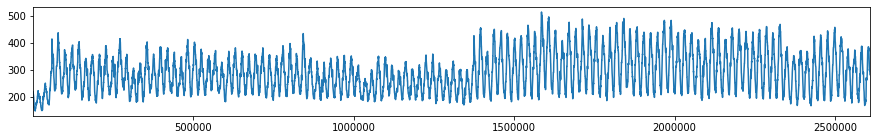

486-1266


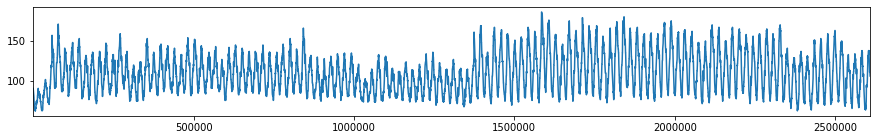

486-1267


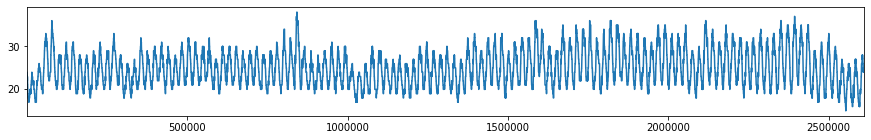

486-1268


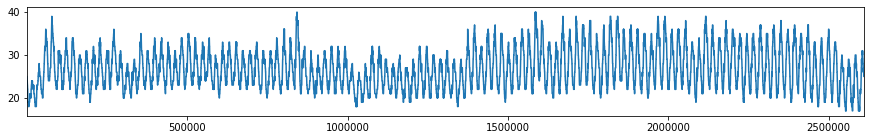

487-1252


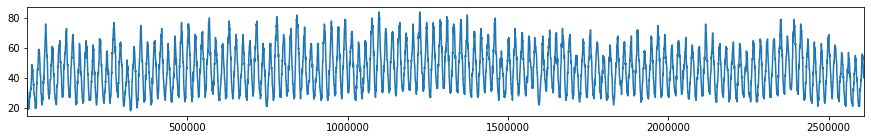

487-1253


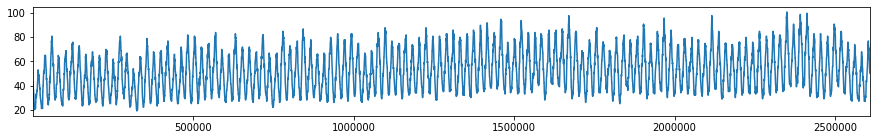

487-1254


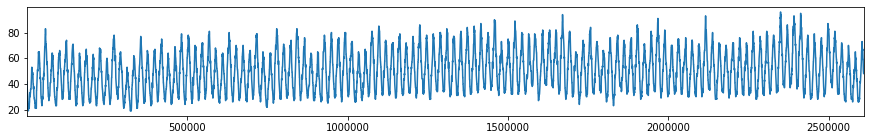

487-1255


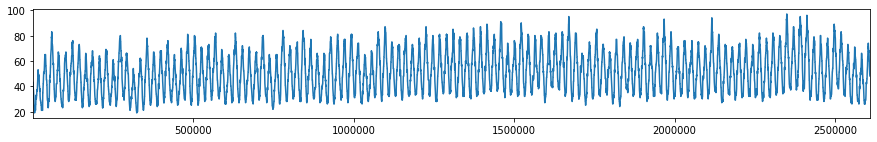

487-1256


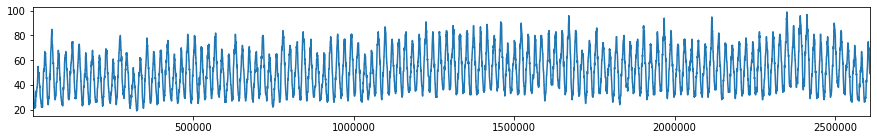

487-1257


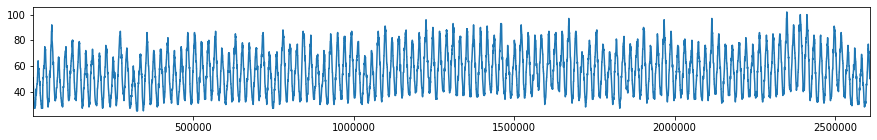

487-1258


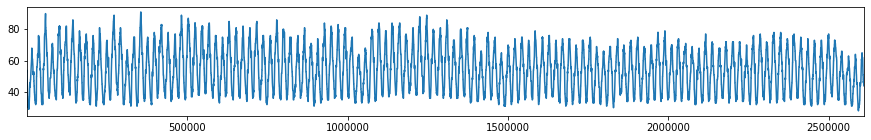

487-1259


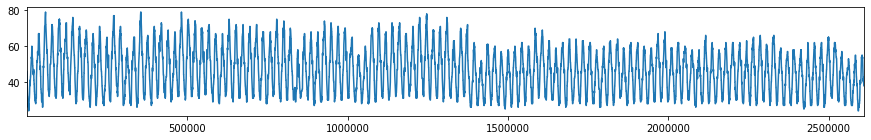

487-1260


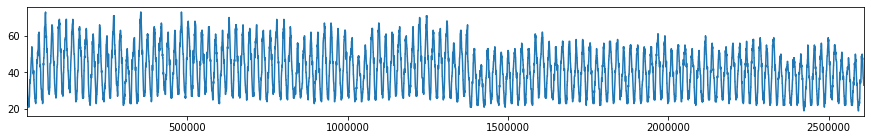

487-1261


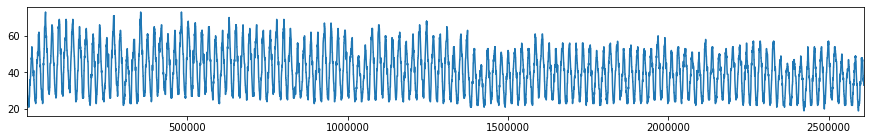

487-1262


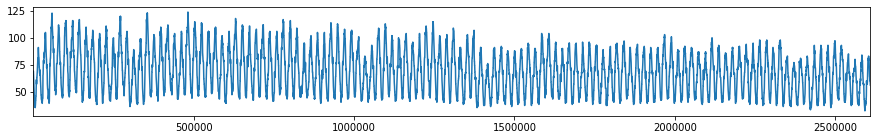

487-1263


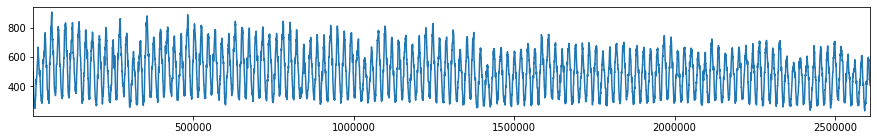

487-1264


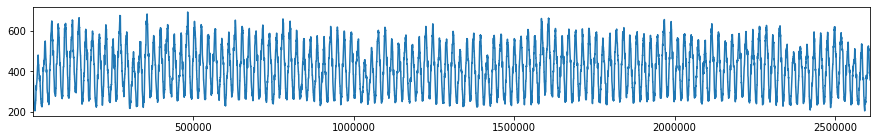

487-1265


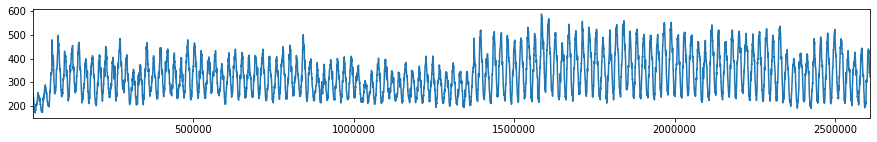

487-1266


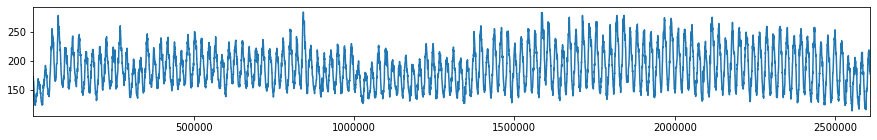

487-1267


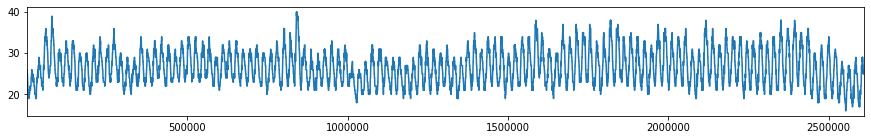

487-1268


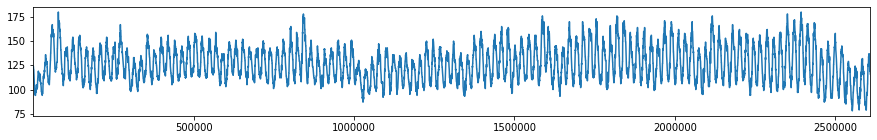

488-1252


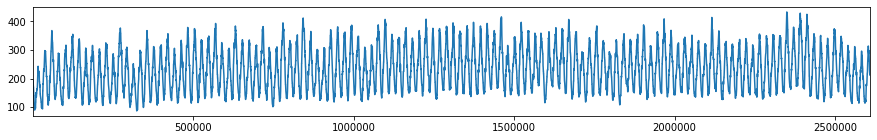

488-1253


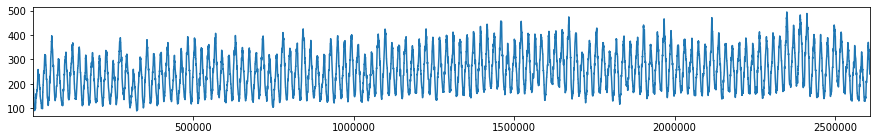

488-1254


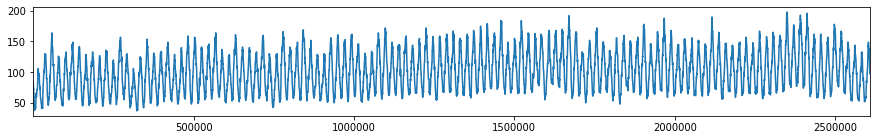

488-1255


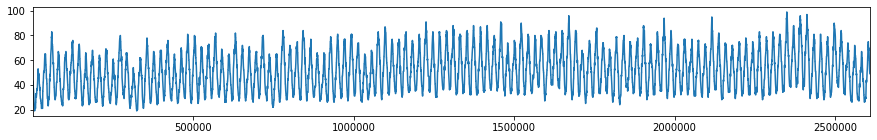

488-1256


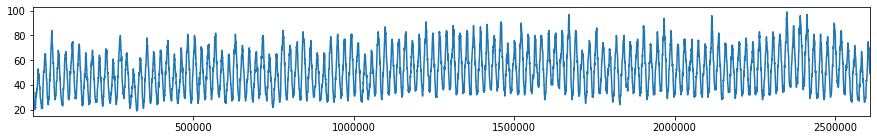

488-1257


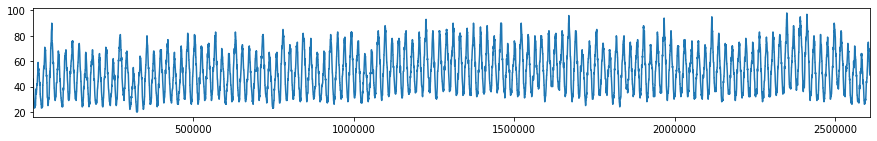

488-1258


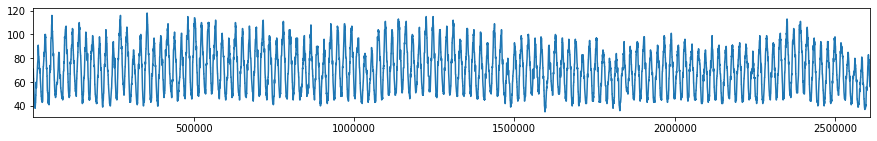

488-1259


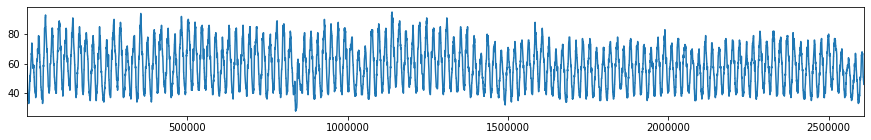

488-1260


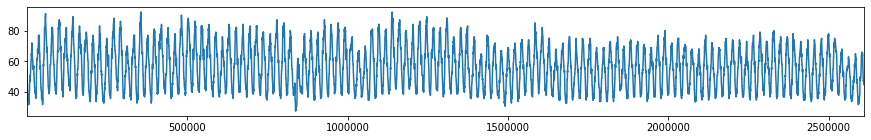

488-1261


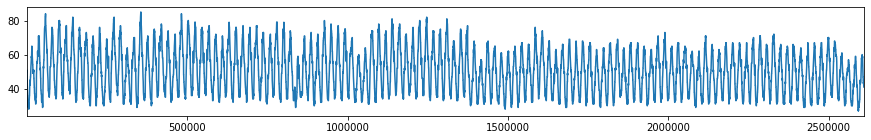

488-1262


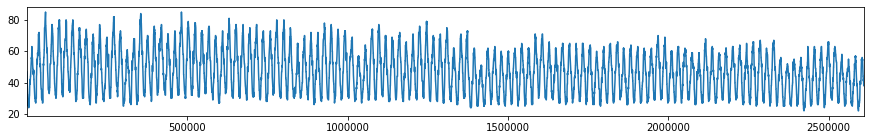

488-1263


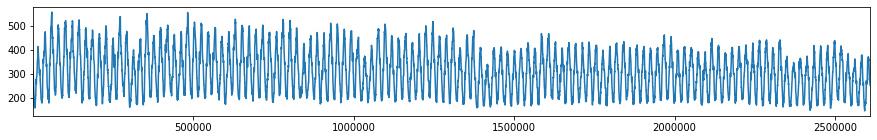

488-1264


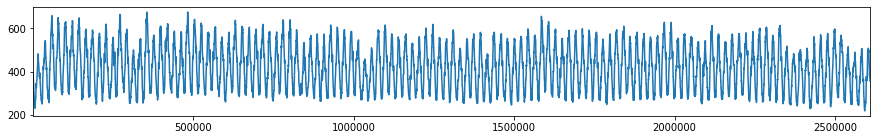

488-1265


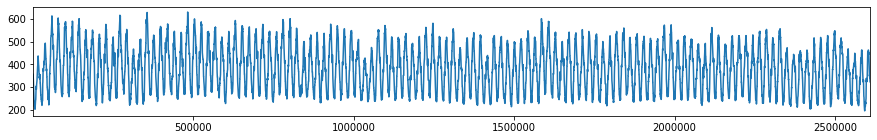

488-1266


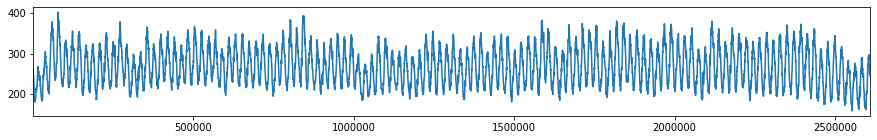

488-1267


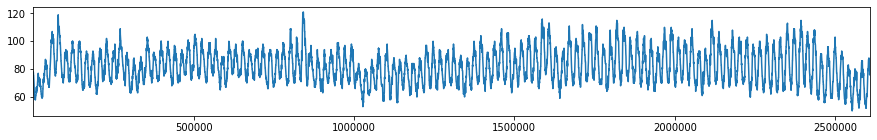

488-1268


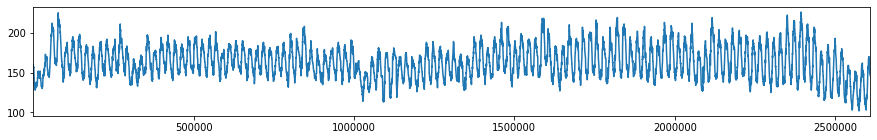

489-1252


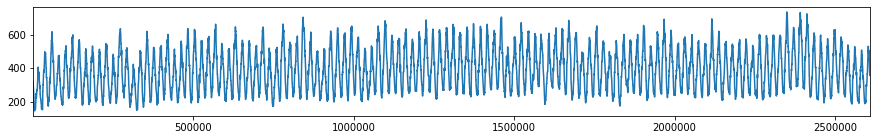

489-1253


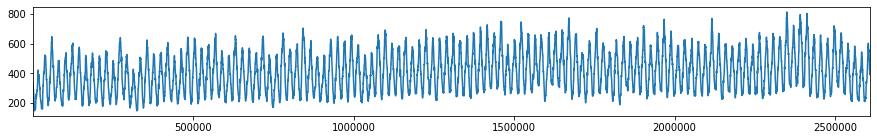

489-1254


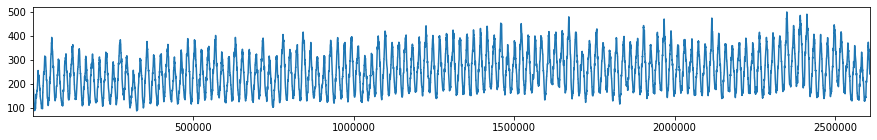

489-1255


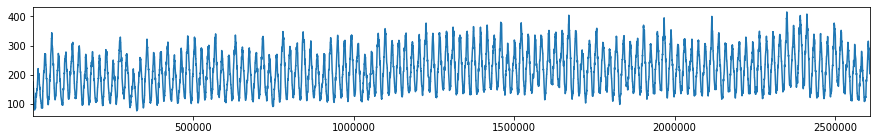

489-1256


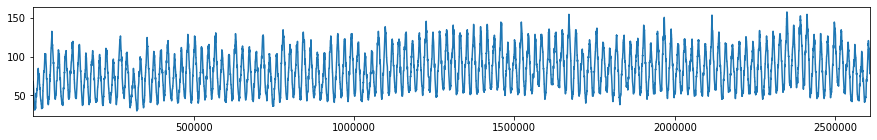

489-1257


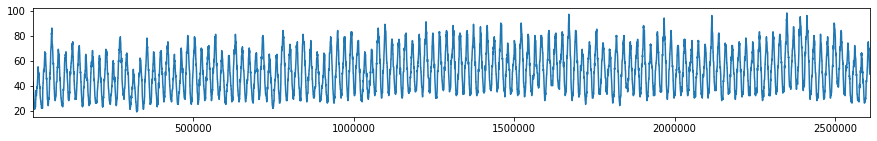

489-1258


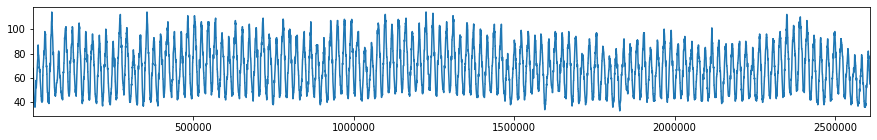

489-1259


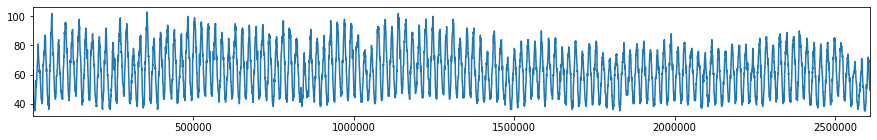

489-1260


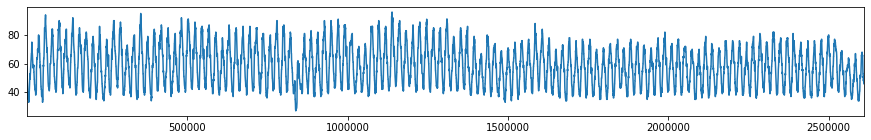

489-1261


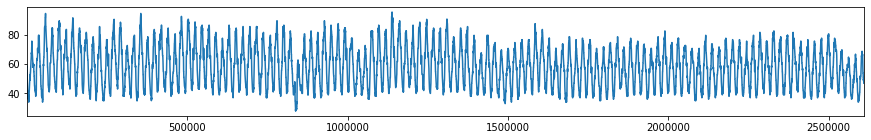

489-1262


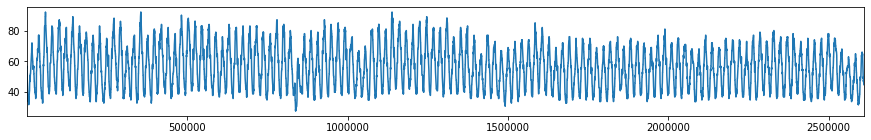

489-1263


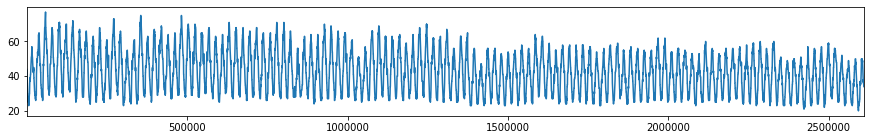

489-1264


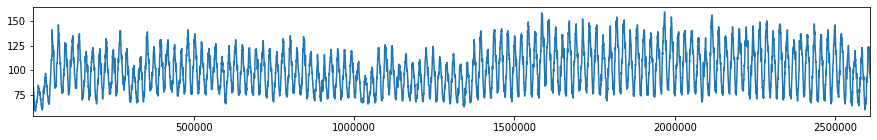

489-1265


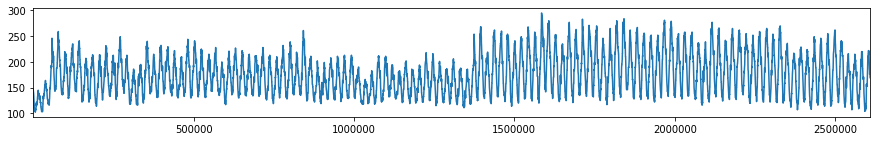

489-1266


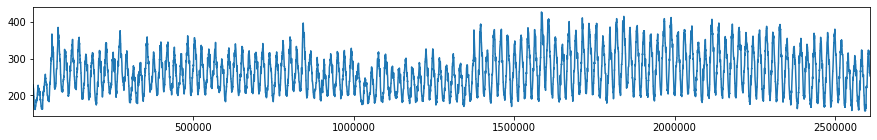

489-1267


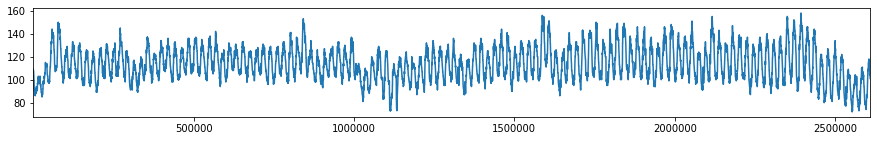

489-1268


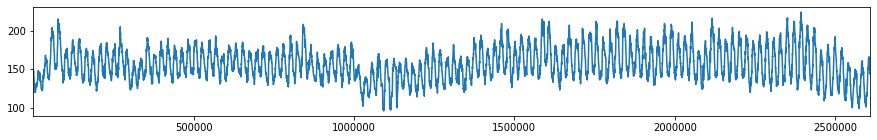

490-1252


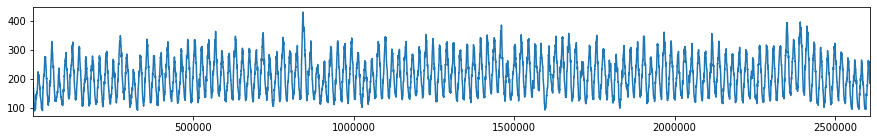

490-1253


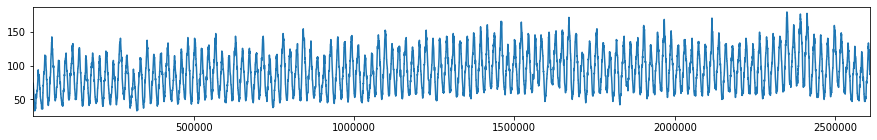

490-1254


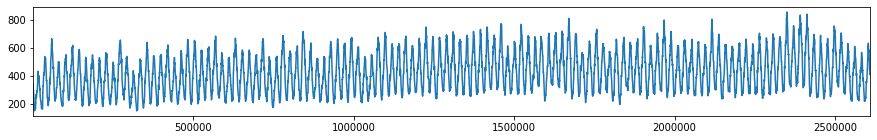

490-1255


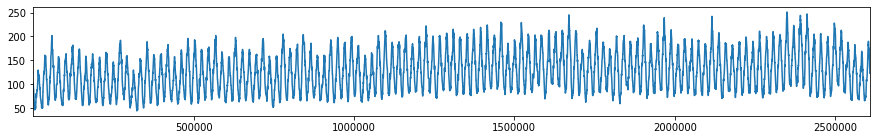

490-1256


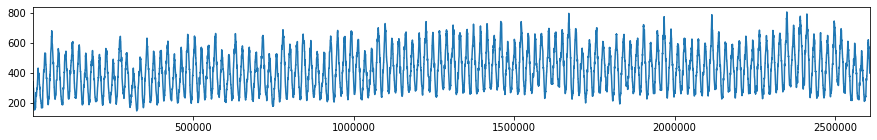

490-1257


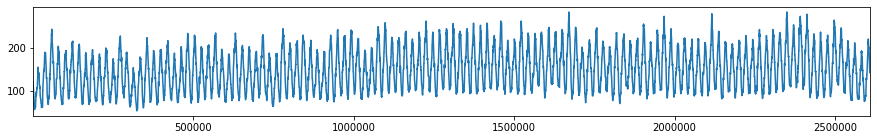

490-1258


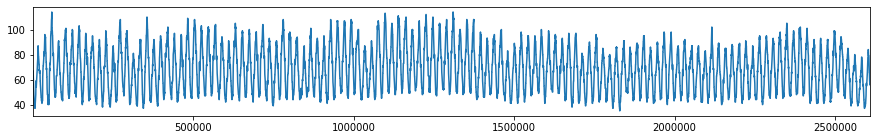

490-1259


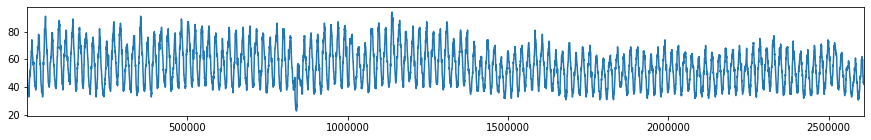

490-1260


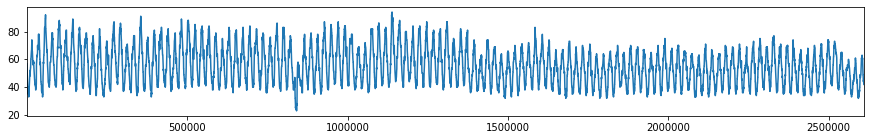

490-1261


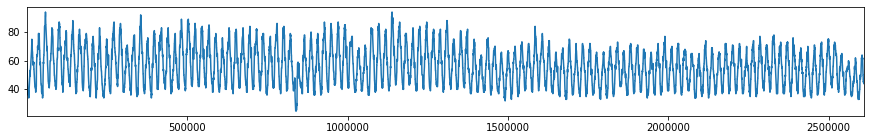

490-1262


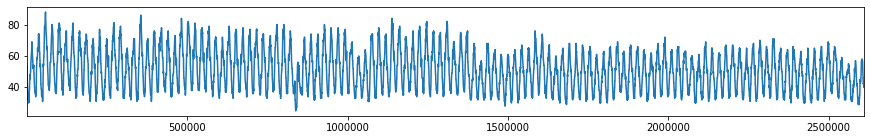

490-1263


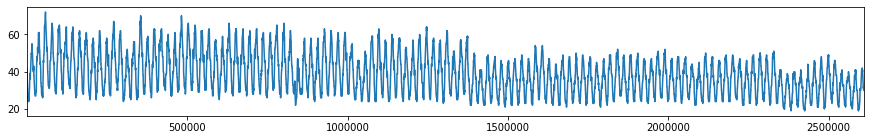

490-1264


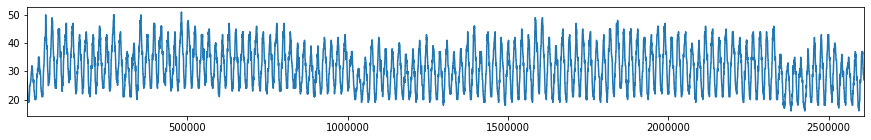

490-1265


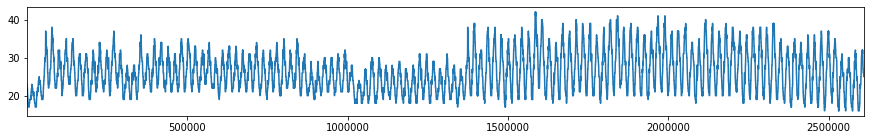

490-1266


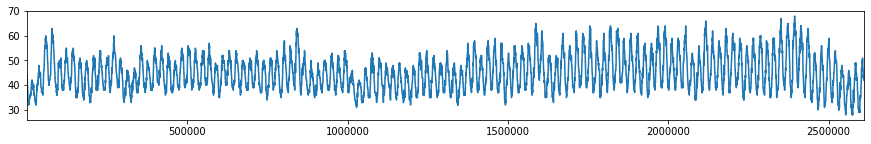

490-1267


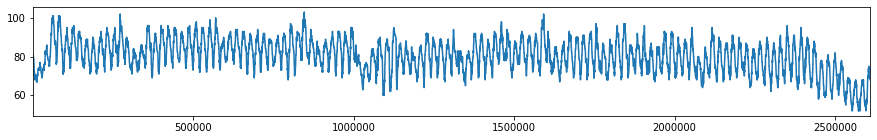

490-1268


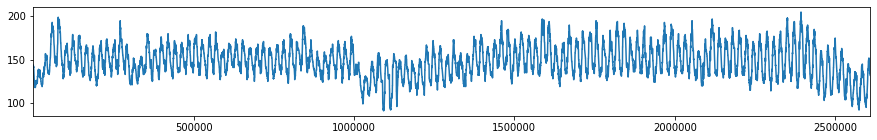

491-1252


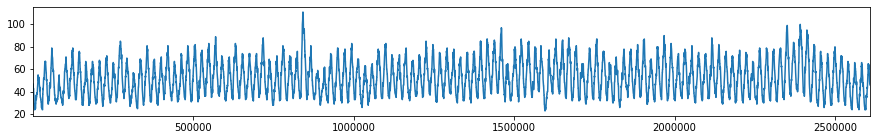

491-1253


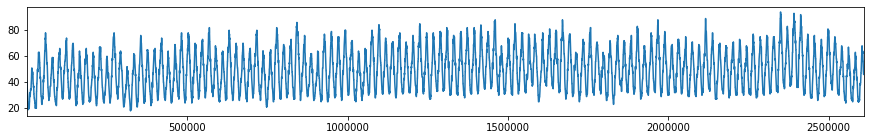

491-1254


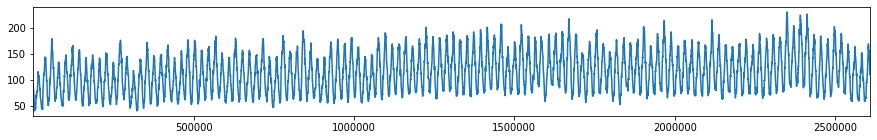

491-1255


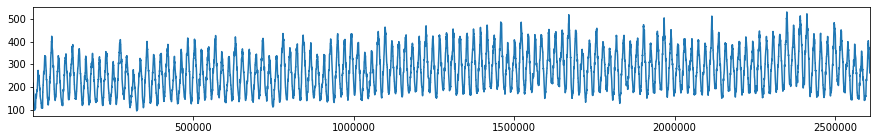

491-1256


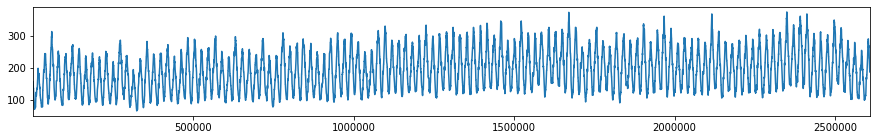

491-1257


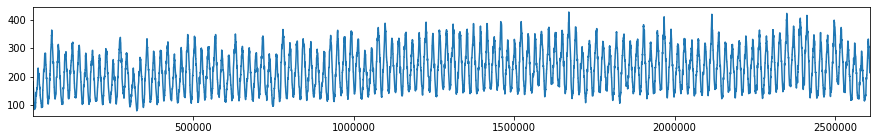

491-1258


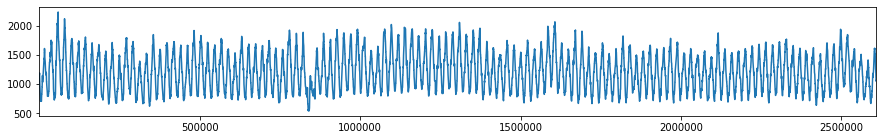

491-1259


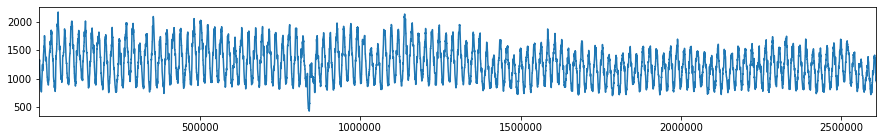

491-1260


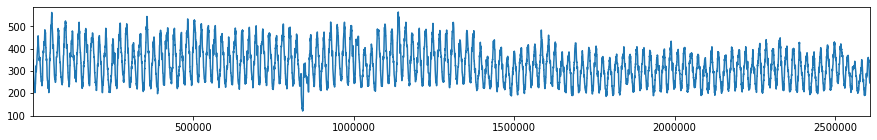

491-1261


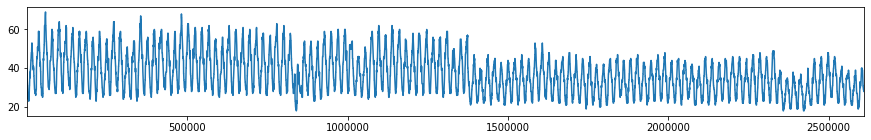

491-1262


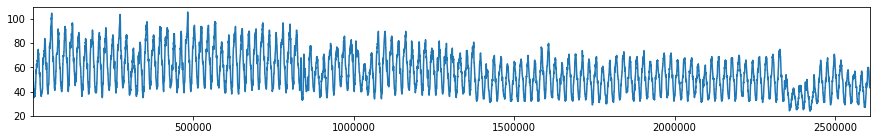

491-1263


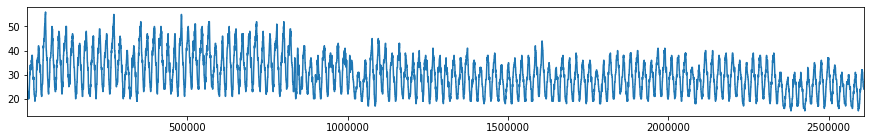

491-1264


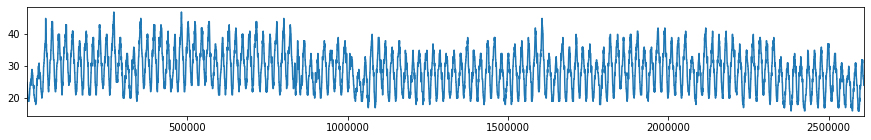

491-1265


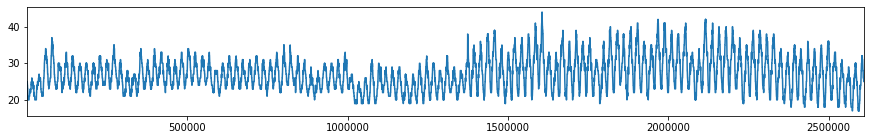

491-1266


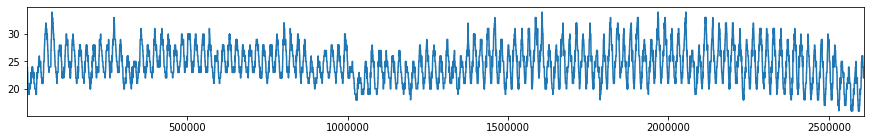

491-1267


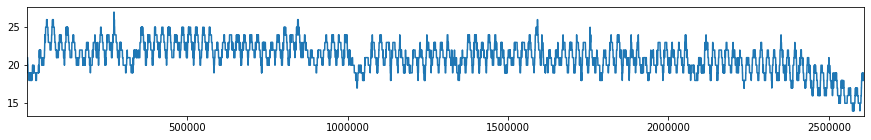

491-1268


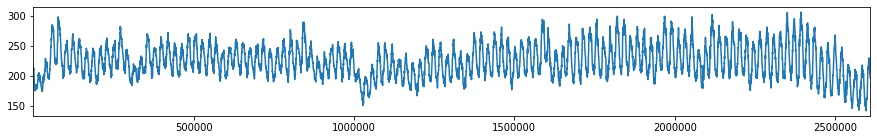

492-1252


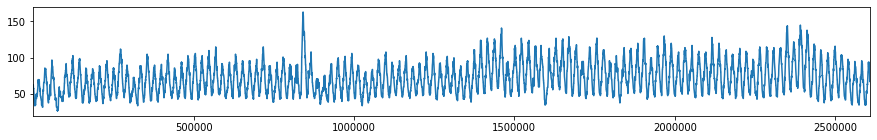

492-1253


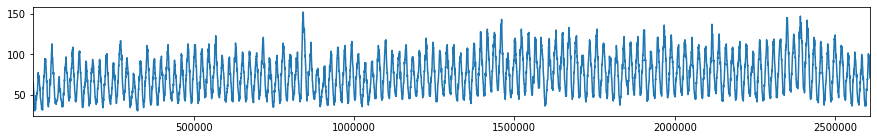

492-1254


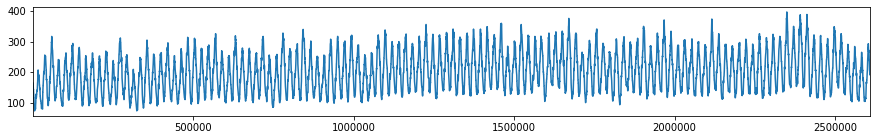

492-1255


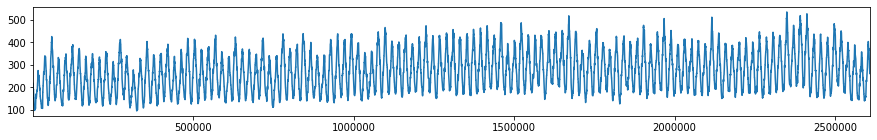

492-1256


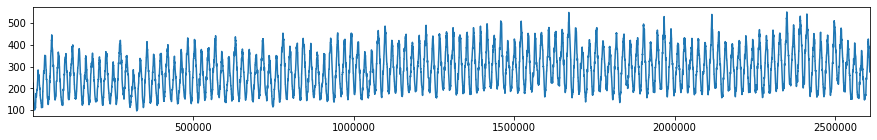

492-1257


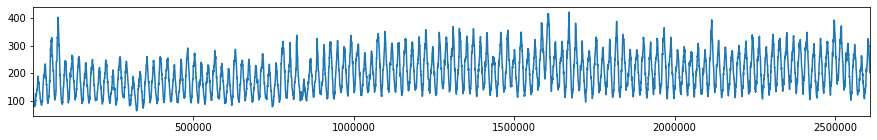

492-1258


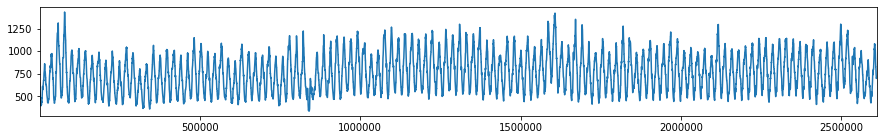

492-1259


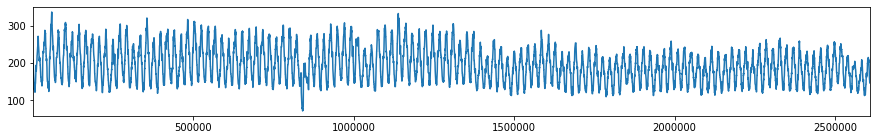

492-1260


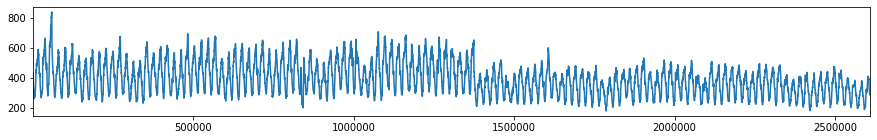

492-1261


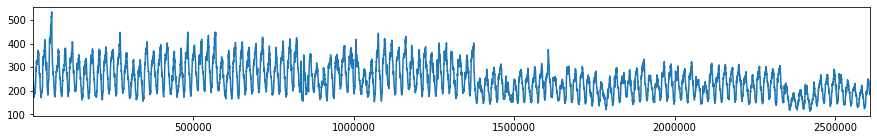

492-1262


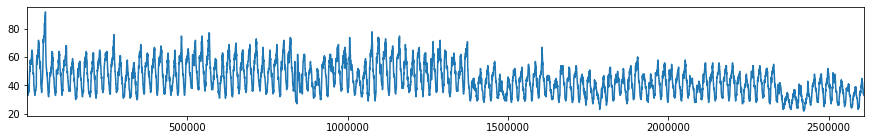

492-1263


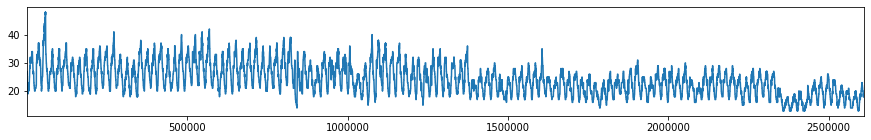

492-1264


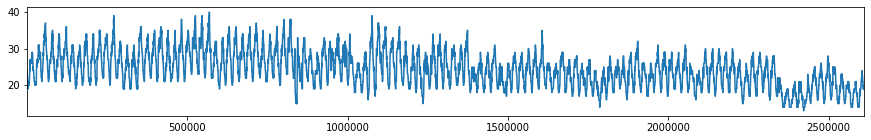

492-1265


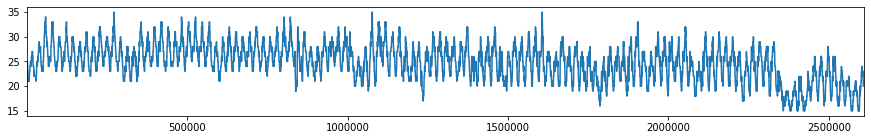

492-1266


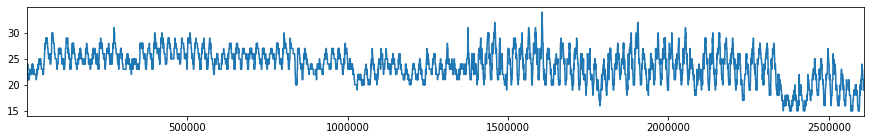

492-1267


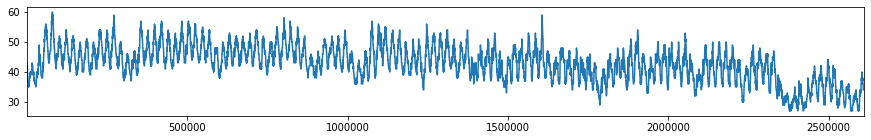

492-1268


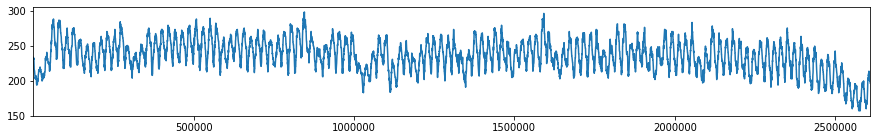

493-1252


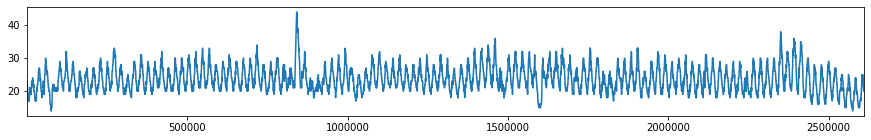

493-1253


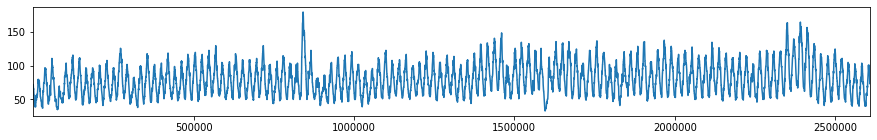

493-1254


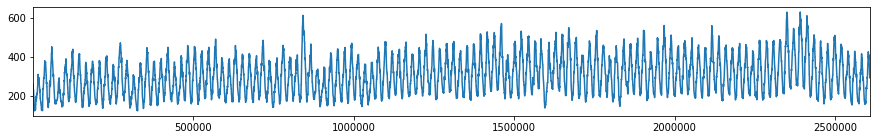

493-1255


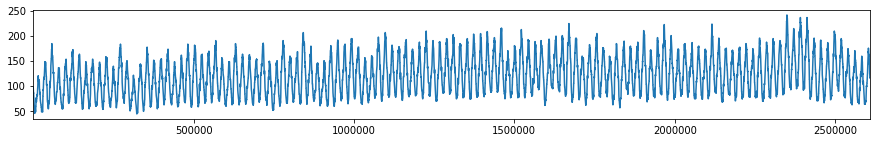

493-1256


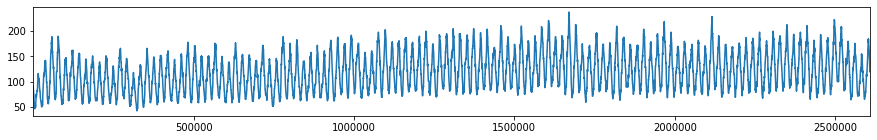

493-1257


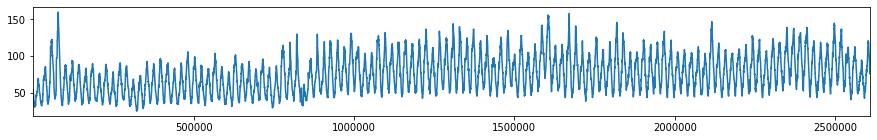

493-1258


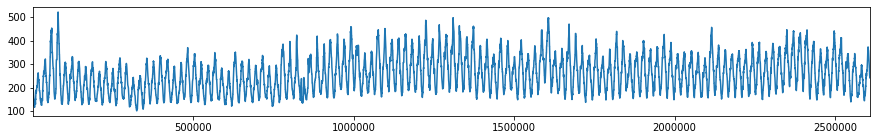

493-1259


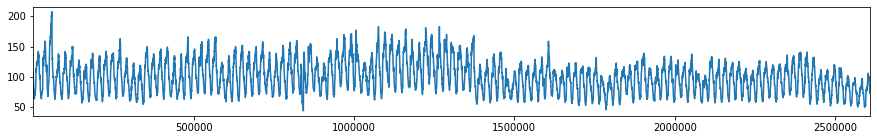

493-1260


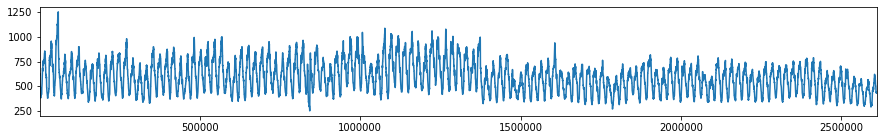

493-1261


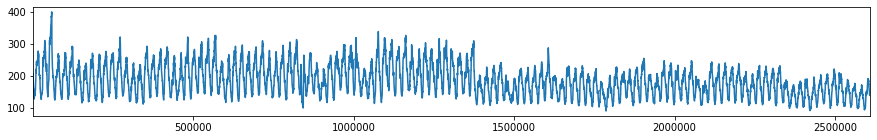

493-1262


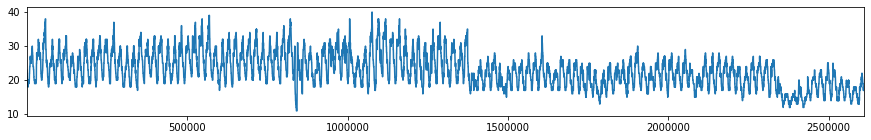

493-1263


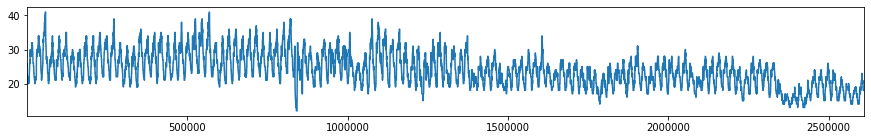

493-1264


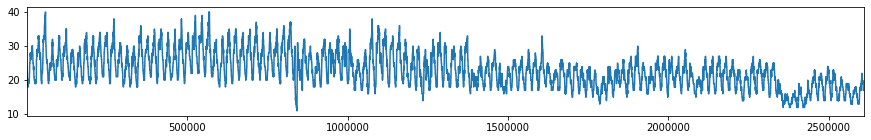

493-1265


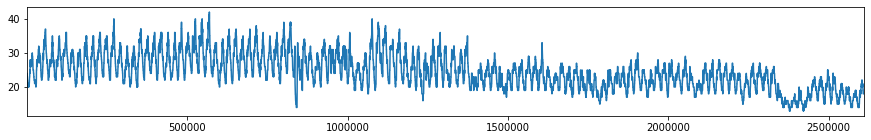

493-1266


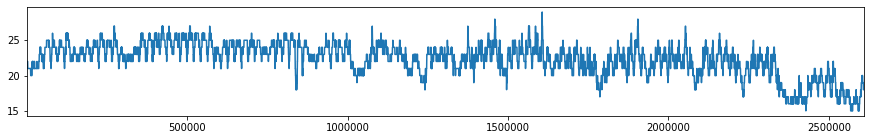

493-1267


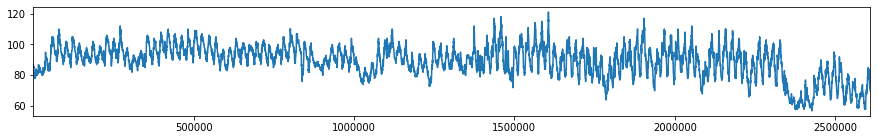

493-1268


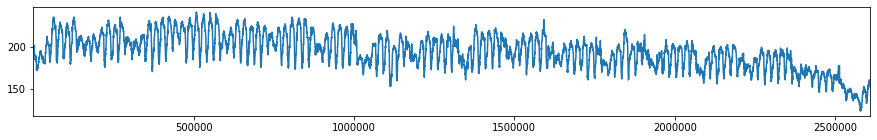

494-1252


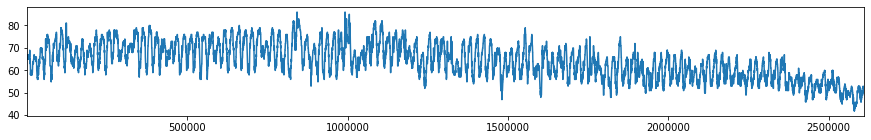

494-1253


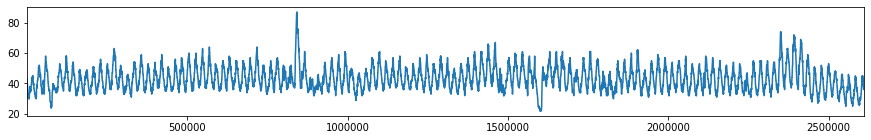

494-1254


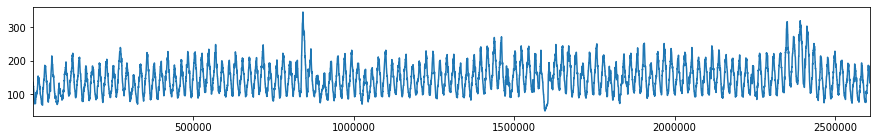

494-1255


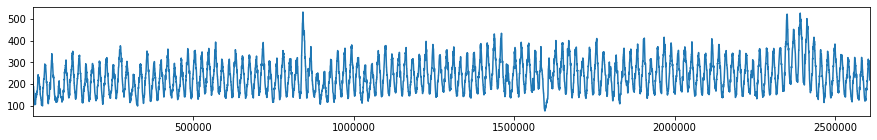

494-1256


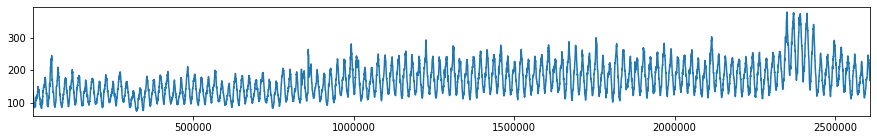

494-1257


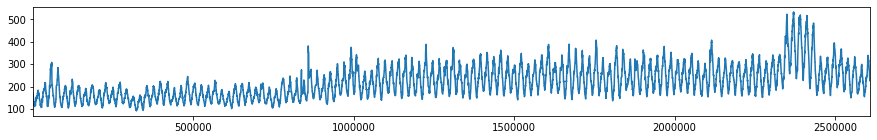

494-1258


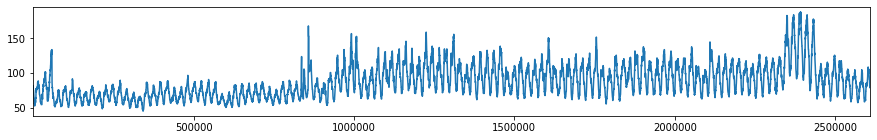

494-1259


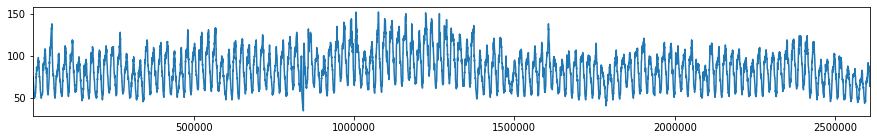

494-1260


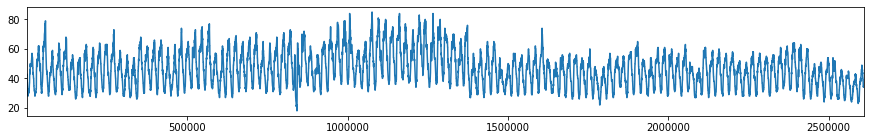

494-1261


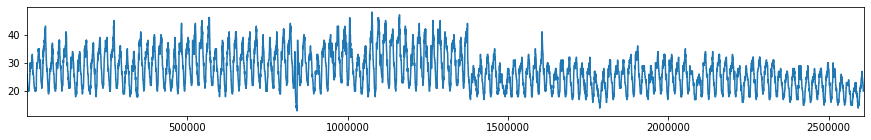

494-1262


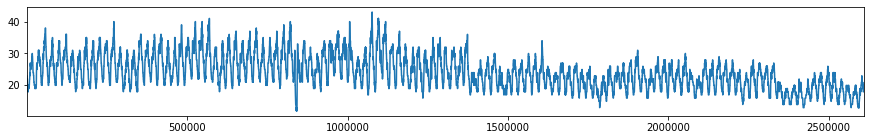

494-1263


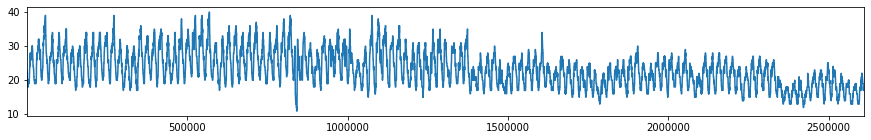

494-1264


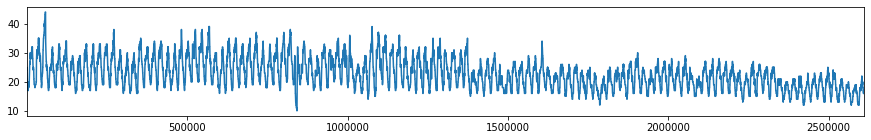

494-1265


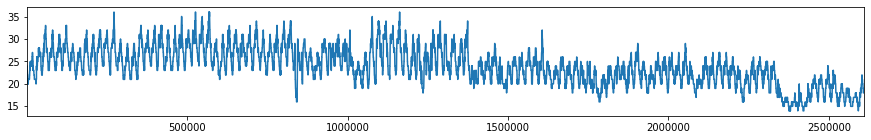

494-1266


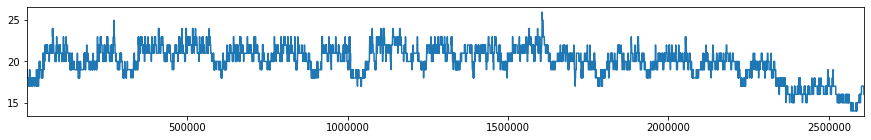

494-1267


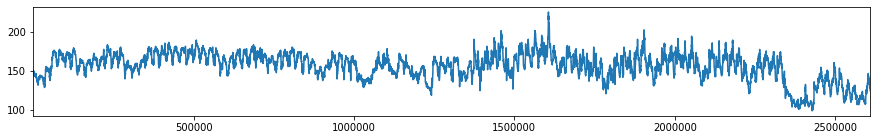

494-1268


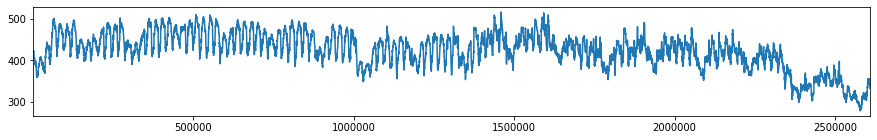

495-1252


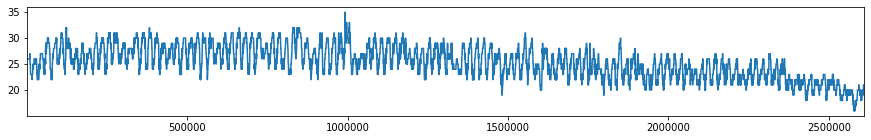

495-1253


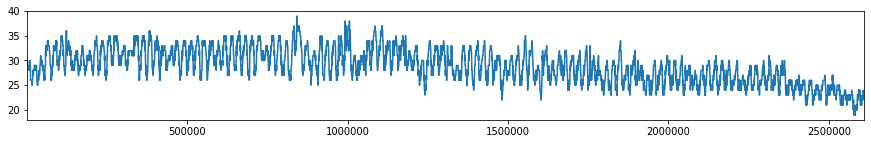

495-1254


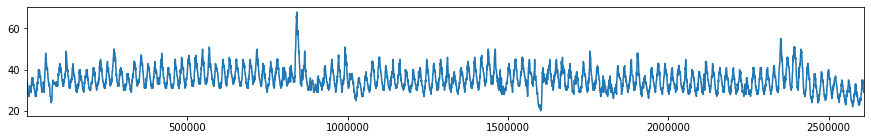

495-1255


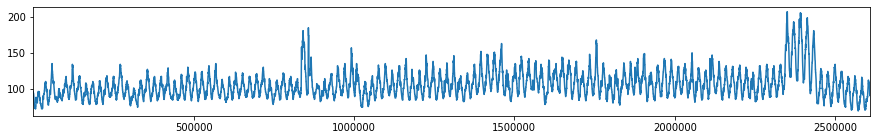

495-1256


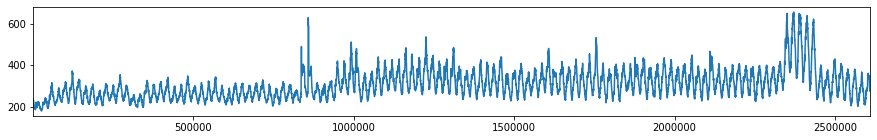

495-1257


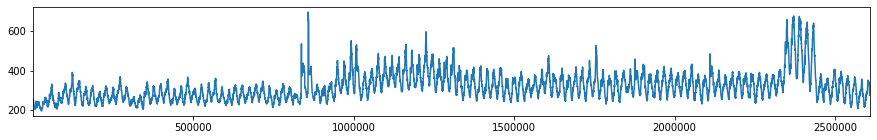

495-1258


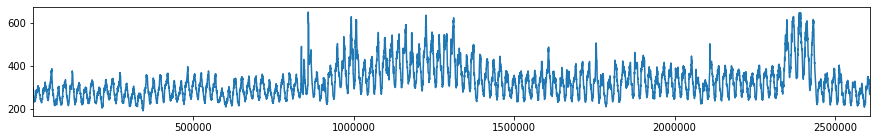

495-1259


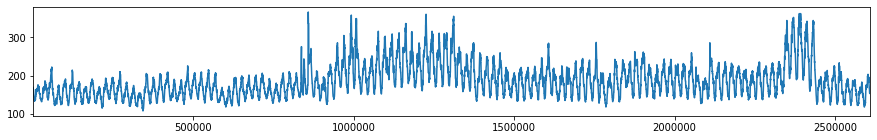

495-1260


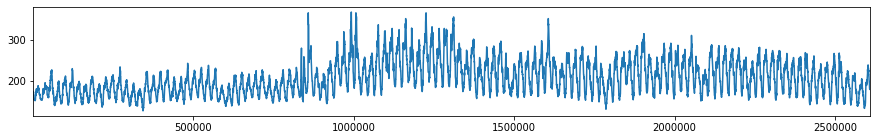

495-1261


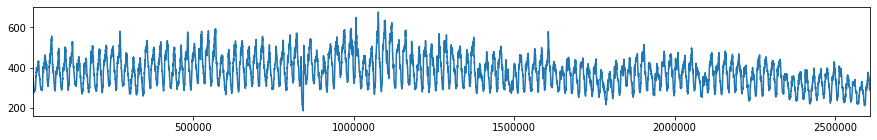

495-1262


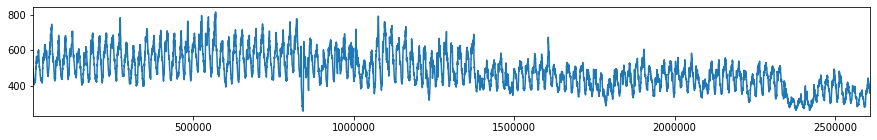

495-1263


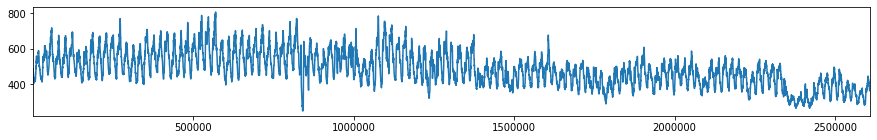

495-1264


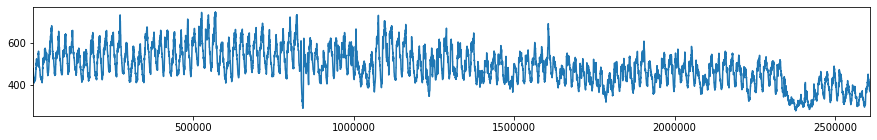

495-1265


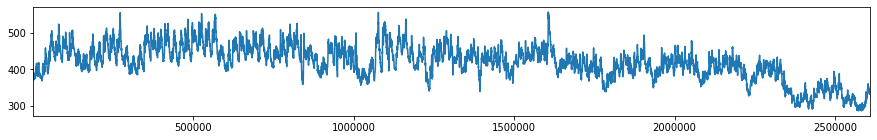

495-1266


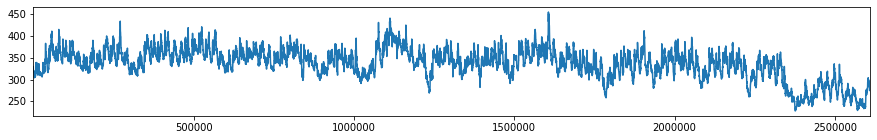

495-1267


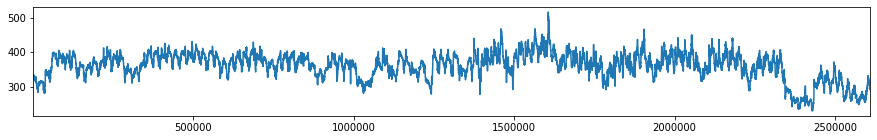

495-1268


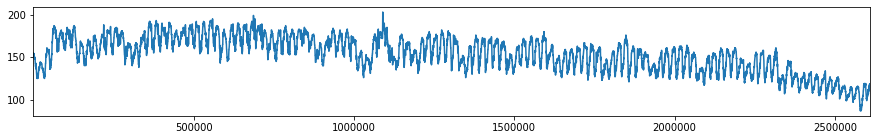

496-1252


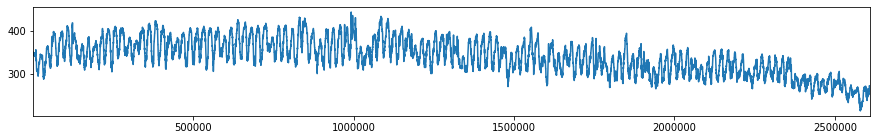

496-1253


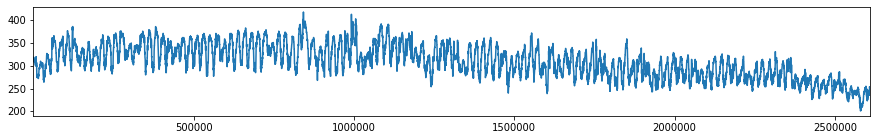

496-1254


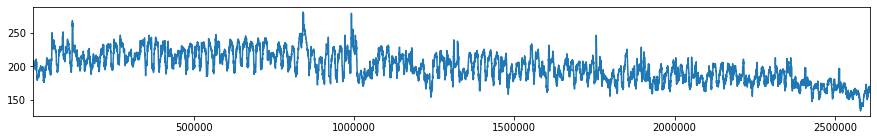

496-1255


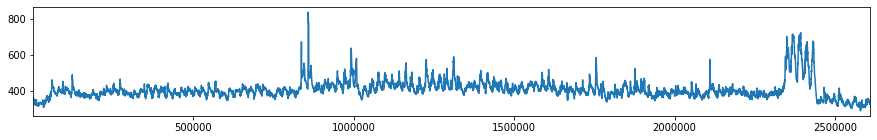

496-1256


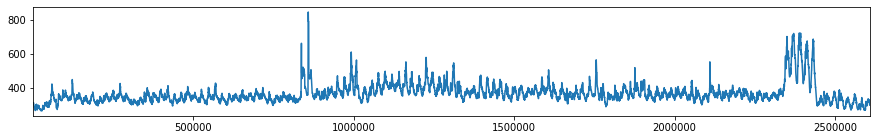

496-1257


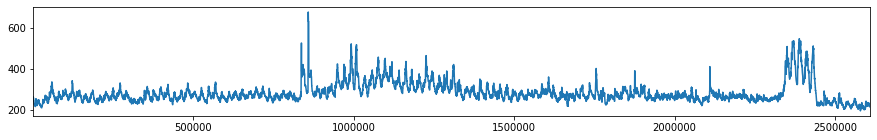

496-1258


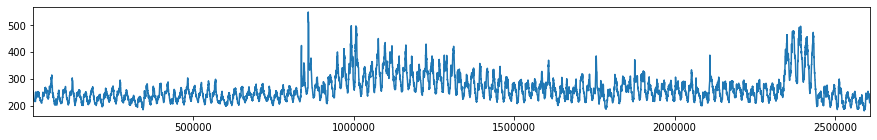

496-1259


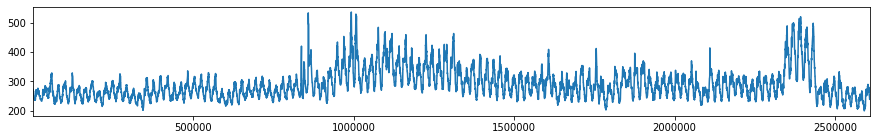

496-1260


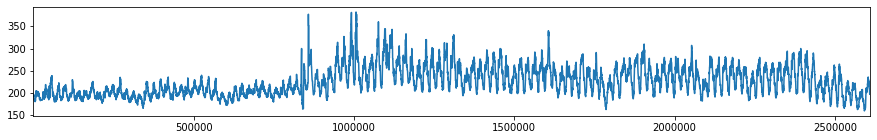

496-1261


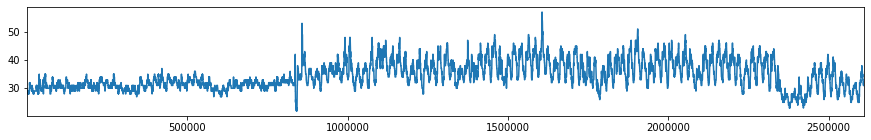

496-1262


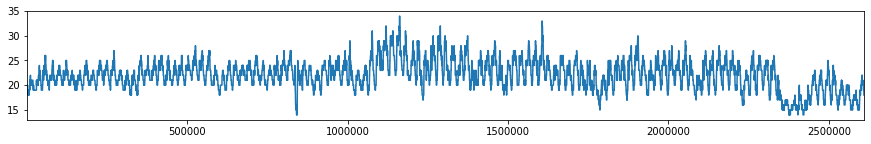

496-1263


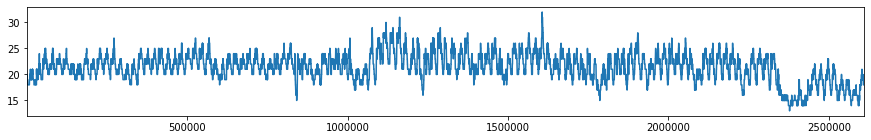

496-1264


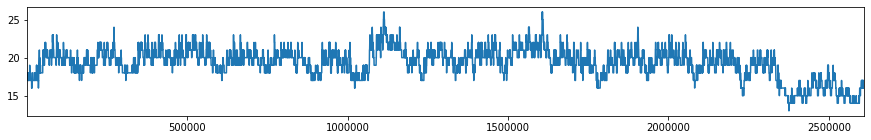

496-1265


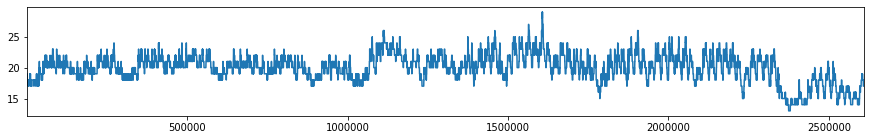

496-1266


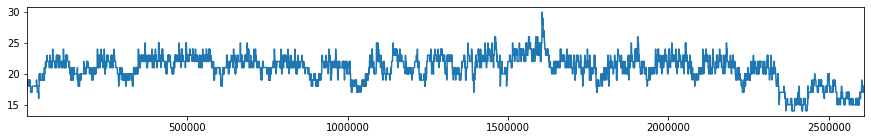

496-1267


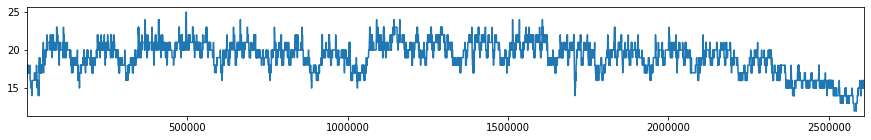

496-1268


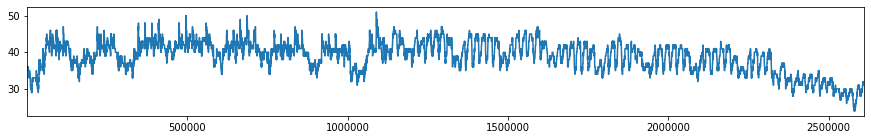

497-1252


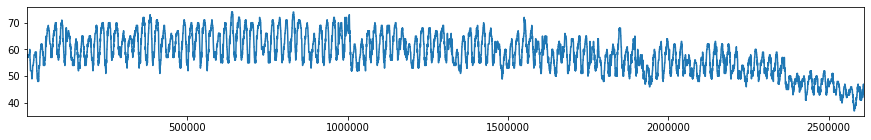

497-1253


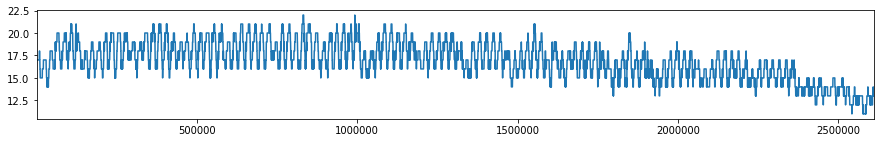

497-1254


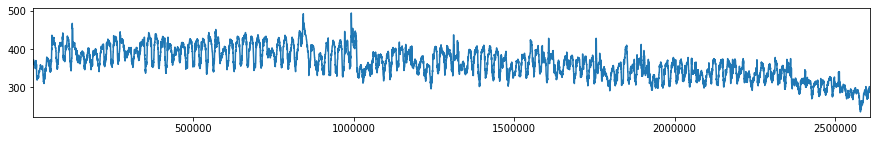

497-1255


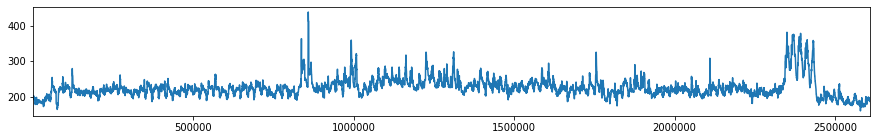

497-1256


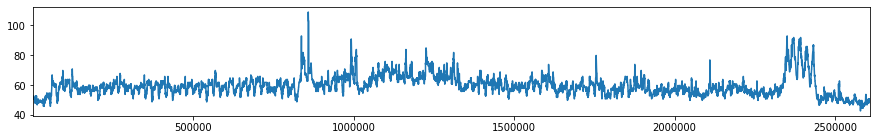

497-1257


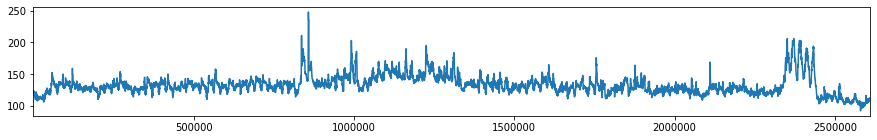

497-1258


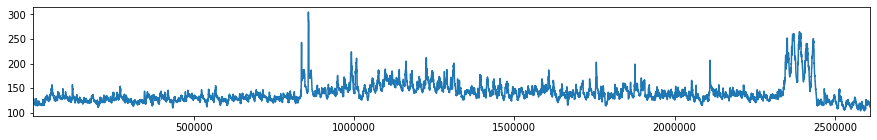

497-1259


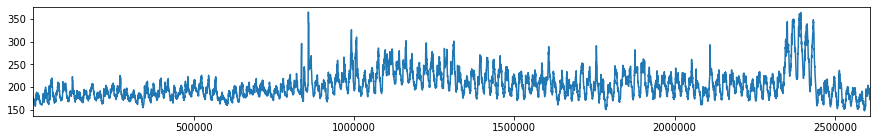

497-1260


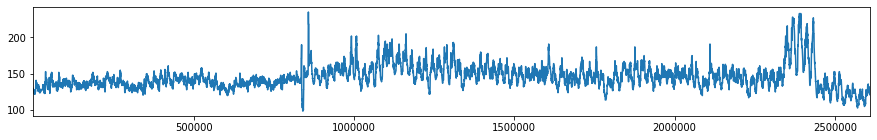

497-1261


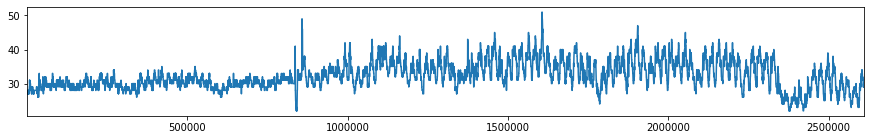

497-1262


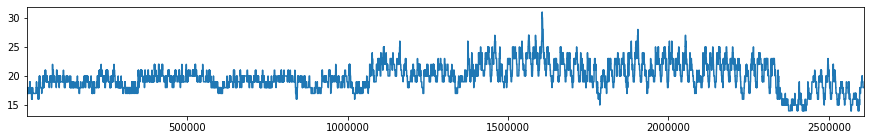

497-1263


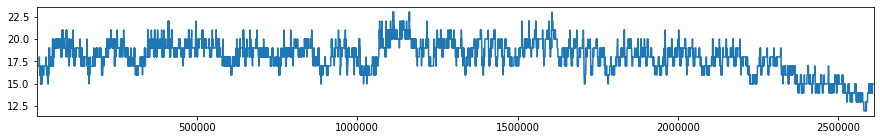

497-1264


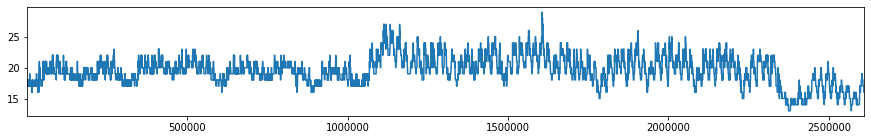

497-1265


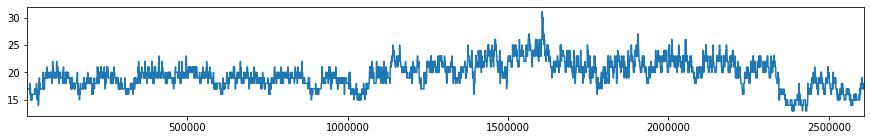

497-1266


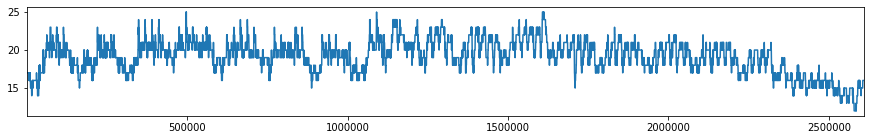

497-1267


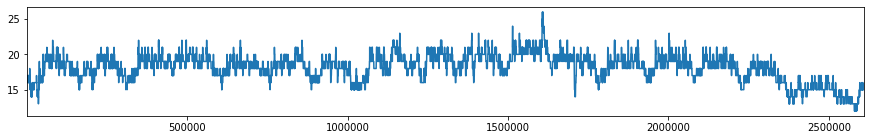

497-1268


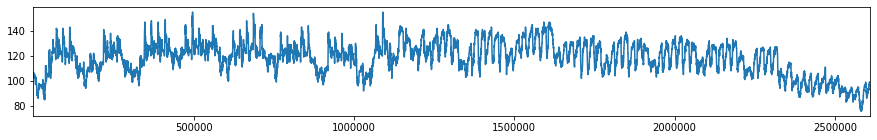

498-1252


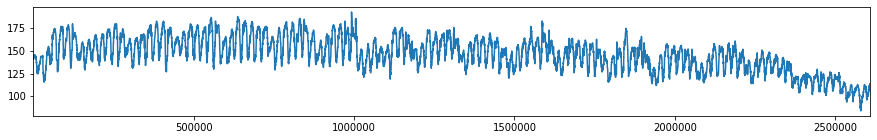

498-1253


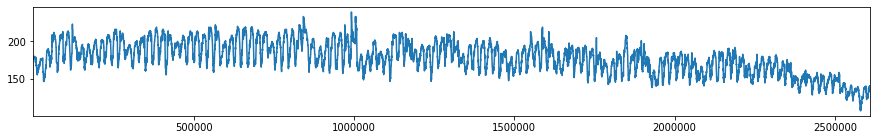

498-1254


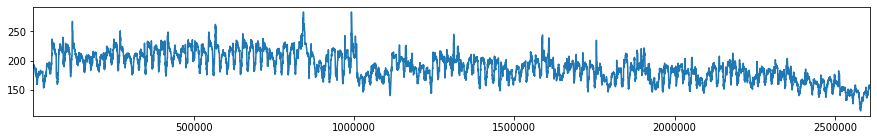

498-1255


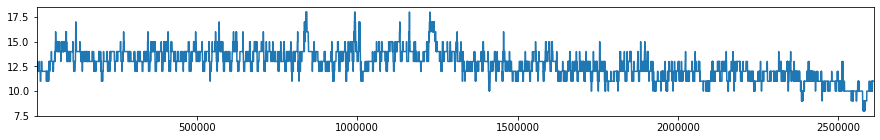

498-1256


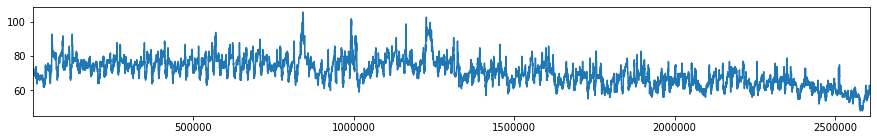

498-1257


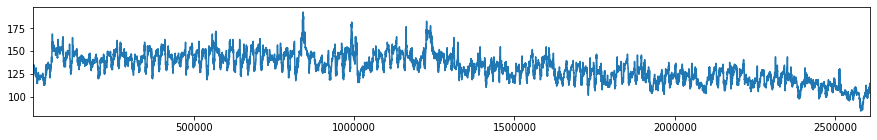

498-1258


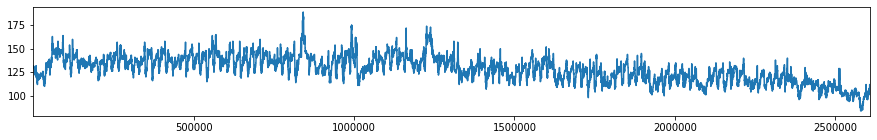

498-1259


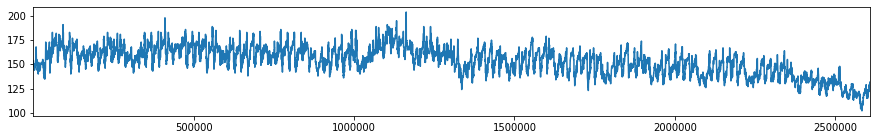

498-1260


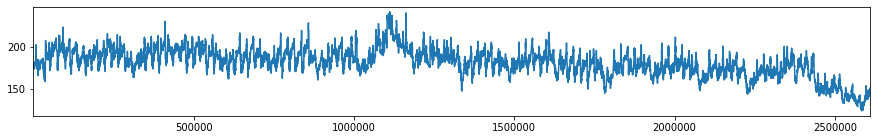

498-1261


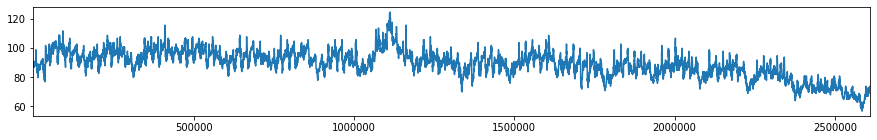

498-1262


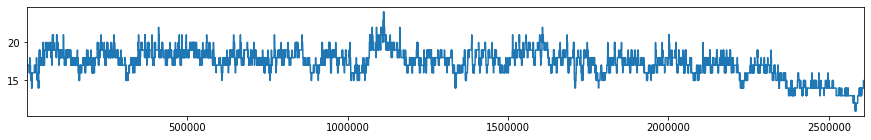

498-1263


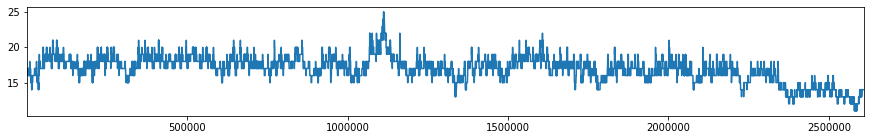

498-1264


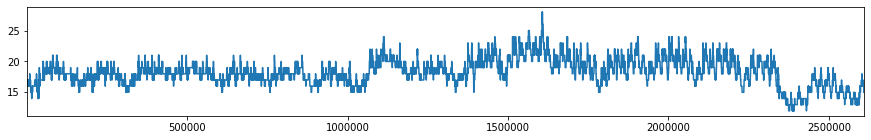

498-1265


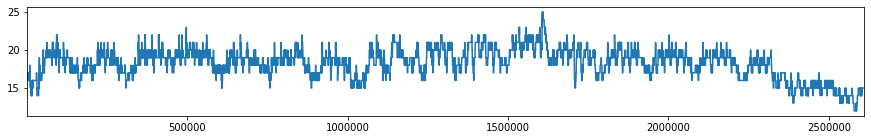

498-1266


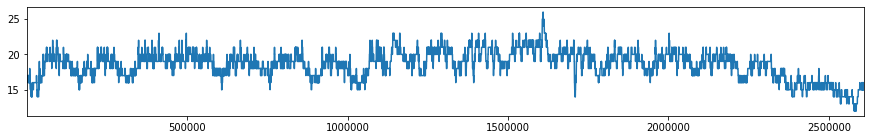

498-1267


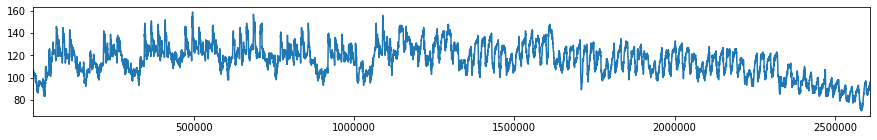

498-1268


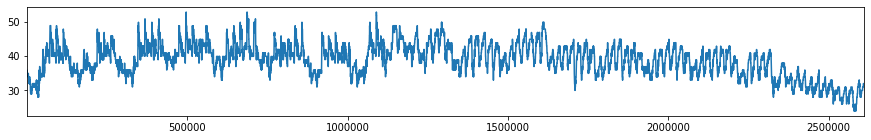

In [30]:
for i, k in agg_by_cell:
    print(i)
    k['nr_people'].plot(figsize = (15, 2))
    plt.show()

### Esaminando la summary si possono ricavare gli intervalli in cui i dati variano.

In [4]:
## summary
data.describe()

,nr_people,hours,minutes
count,2.609568e+06,2.609568e+06,2.609568e+06
mean,1.504546e+02,1.150000e+01,2.250000e+01
std,1.801338e+02,6.922188e+00,1.677051e+01
min,8.000000e+00,0.000000e+00,0.000000e+00
25%,3.400000e+01,5.750000e+00,1.125000e+01
50%,7.700000e+01,1.150000e+01,2.250000e+01
75%,2.110000e+02,1.725000e+01,3.375000e+01
max,2.230000e+03,2.300000e+01,4.500000e+01


In [10]:
d = data.describe()
global_percent_75 = d['nr_people']['75%']
global_percent_50 = d['nr_people']['50%']
global_percent_25 = d['nr_people']['25%']
global_mean = d['nr_people']['mean']
global_max = d['nr_people']['max']
global_min = d['nr_people']['min']
print(global_max, global_percent_75, global_percent_50, global_mean, global_percent_25,global_min )

2230.0 211.0 77.0 150.45458865222136 34.0 8.0


In [11]:
count = 0
values = []
is_low_activity = []
is_medium_activity = []
is_high_activity = []
is_very_high_activity = []

cell_activity = {}

count = 0
for i,k in agg_by_cell:
    
    cell_i = i
    values = k.describe()
    max_cell = values['nr_people']['75%']
    percent_75_cell = values['nr_people']['75%']
    percent_50_cell = values['nr_people']['50%']
    percent_25_cell = values['nr_people']['25%']
    mean_cell = values['nr_people']['mean']
    
    #for index, row in k.iterrows():   
    if max_cell < global_percent_25 :
            #is_low_activity.append(1)
            #is_medium_activity.append(0)
            #is_high_activity.append(0)
            #is_very_high_activity.append(0)
            cell_activity[cell_i] = 'is_low'
            
    if max_cell > global_percent_25 and max_cell < global_mean:
            #is_low_activity.append(0)
            #is_medium_activity.append(1)
            #is_high_activity.append(0)
            #is_very_high_activity.append(0)
            cell_activity[cell_i] = 'is_medium'
            
    if max_cell > global_mean and max_cell < global_percent_75:
            #is_low_activity.append(0)
            #is_medium_activity.append(0)
            #is_high_activity.append(1)
            #is_very_high_activity.append(0)
            cell_activity[cell_i] = 'is_high'
        
    if max_cell > global_mean and max_cell > global_percent_75:
            #is_low_activity.append(0)
            #is_medium_activity.append(0)
            #is_high_activity.append(0)
            #is_very_high_activity.append(1)
            cell_activity[cell_i] = 'is_very_high'
   

In [12]:
len(cell_activity)

221

In [13]:
count = 0
for index, row in data.iterrows():
    #print(index, row)
    
    cell_number = row['cell_num']   
    activity_level = cell_activity[cell_number]
    
    if activity_level == 'is_low':
            is_low_activity.append(1)
            is_medium_activity.append(0)
            is_high_activity.append(0)
            is_very_high_activity.append(0)
           
    if activity_level == 'is_medium':
            is_low_activity.append(0)
            is_medium_activity.append(1)
            is_high_activity.append(0)
            is_very_high_activity.append(0)
             
    if activity_level == 'is_high':
            is_low_activity.append(0)
            is_medium_activity.append(0)
            is_high_activity.append(1)
            is_very_high_activity.append(0)
            
    if activity_level == 'is_very_high':
            is_low_activity.append(0)
            is_medium_activity.append(0)
            is_high_activity.append(0)
            is_very_high_activity.append(1)  

In [14]:
data['is_low_activity'] = is_low_activity
data['is_medium_activity'] = is_medium_activity
data['is_high_activity'] = is_high_activity
data['is_very_high_activity'] = is_very_high_activity

In [15]:
very_high_activity_data = data[data['is_very_high_activity']==1]
high_activity_data = data[data['is_high_activity']==1]
medium_activity_data = data[data['is_medium_activity']==1]
low_activity_data = data[data['is_low_activity']==1]

In [16]:
print(len(very_high_activity_data))
print(len(high_activity_data))
print(len(medium_activity_data))
print(len(low_activity_data))

791136
212544
1074528
531360


### Come variano i valori di ogni tipo di cella

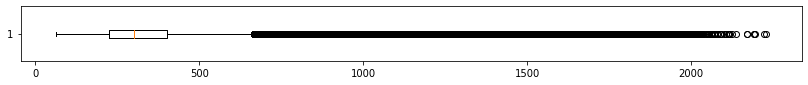

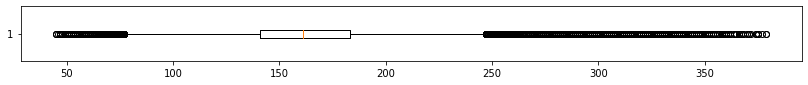

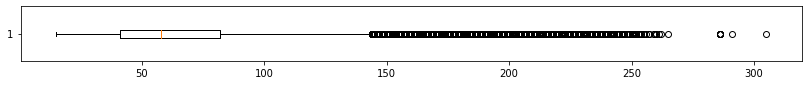

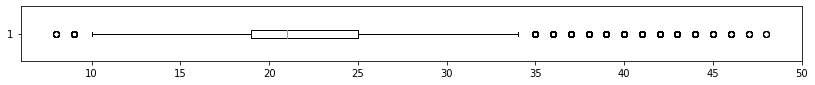

In [17]:
plt.figure(figsize = (14,1))
plt.boxplot(very_high_activity_data['nr_people'], vert= False);
plt.show()
plt.figure(figsize = (14,1))
plt.boxplot(high_activity_data['nr_people'], vert= False);
plt.show()  
plt.figure(figsize = (14,1))
plt.boxplot(medium_activity_data['nr_people'], vert= False);
plt.show() 
plt.figure(figsize = (14,1))
plt.boxplot(low_activity_data['nr_people'], vert= False);
plt.show() 